<a href="https://www.kaggle.com/code/mukeshkumar95/customer-segmentation-using-k-means-clustering?scriptVersionId=367915125" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mukeshkumar95/customer-sales-data/customer_segmentation_dataset_5000.csv


In [2]:
import pandas as pd
customers=pd.read_csv("/kaggle/input/datasets/mukeshkumar95/customer-sales-data/customer_segmentation_dataset_5000.csv")

In [3]:
customers.head()

,CustomerID,Gender,Age,AnnualIncome,SpendingScore
0,1,Female,31,94592,97
1,2,Male,22,27314,28
2,3,Male,57,91395,52
3,4,Male,25,27164,21
4,5,Male,64,106062,76


*Customer ID columns are not required for this clustering analysis. Also, the gender column is not required, but it can be used on a case-by-case basis or if I want to further cluster the data into customers who buy high-end watches vs. mid-level watches by men and women.*

In [4]:
#dropping irrelevant columns
customers=customers.drop(["CustomerID","Gender"],axis=1)
customers.head()

,Age,AnnualIncome,SpendingScore
0,31,94592,97
1,22,27314,28
2,57,91395,52
3,25,27164,21
4,64,106062,76


In [5]:
# Checking missing values
customers.isna().sum().sum()


np.int64(0)

In [6]:
# Checking duplicate rows
customers.duplicated().sum()

np.int64(0)

# Preprocessing and Pipeline

*Standardising the data so it is on a smaller scale, same ratio, same distance between them and helps our clustering model*


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor=ColumnTransformer(
    transformers=[("num", StandardScaler(),["Age","AnnualIncome","SpendingScore"])]
)

In [8]:
#pipeline
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",KMeans(n_clusters=3))
])

pipeline.fit(customers)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'AnnualIncome',
                                                   'SpendingScore'])])),
                ('model', KMeans(n_clusters=3))])

In [9]:
clusters=pipeline.predict(customers)
clusters

array([1, 2, 1, ..., 0, 1, 2], dtype=int32)

In [10]:
#adding clusters to a dataframe
customers["cluster"]=clusters
customers.head()

,Age,AnnualIncome,SpendingScore,cluster
0,31,94592,97,1
1,22,27314,28,2
2,57,91395,52,1
3,25,27164,21,2
4,64,106062,76,1


In [11]:
#finding patterns
customers.groupby("cluster")[["Age","AnnualIncome","SpendingScore"]].mean()

,Age,AnnualIncome,SpendingScore
cluster,,,
0,38.599227,63425.423969,42.567010
1,48.066158,116703.831425,76.290712
2,26.461087,32333.983475,18.688166


From the above we can see that the Group 2 are the luxury buyers, group 1 are deal shoppers, and group 0 are premimum shoppers.

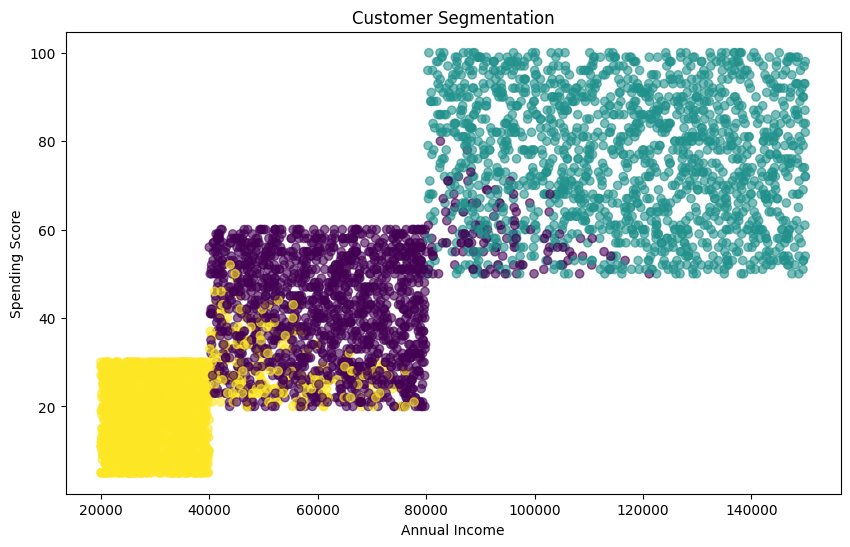

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(customers["AnnualIncome"],
           customers["SpendingScore"],
           c=customers["cluster"],
           alpha=0.6)
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation")
plt.show()

Spending score is higher when a customer is earning a higher salary. There is a clear and positive correlation between ALL three columns.

In [13]:
# Checking if we have used the optimum number of clusters for our model using elbow method

inertia=[] #how tightly grouped the clusters are. Lower means closer, center means more compact.

for k in range(1,11):
    model=KMeans(n_clusters=k, random_state=42)
    model.fit(customers)
    inertia.append(model.inertia_)


inertia

[7245402596046.616,
 1714931634247.0725,
 684309732165.2119,
 389994021140.7634,
 261362030227.2868,
 183307791072.97723,
 134381990086.64116,
 101136947422.46808,
 76472752622.59175,
 67808466776.48636]

Text(0.5, 1.0, 'Elbow method')

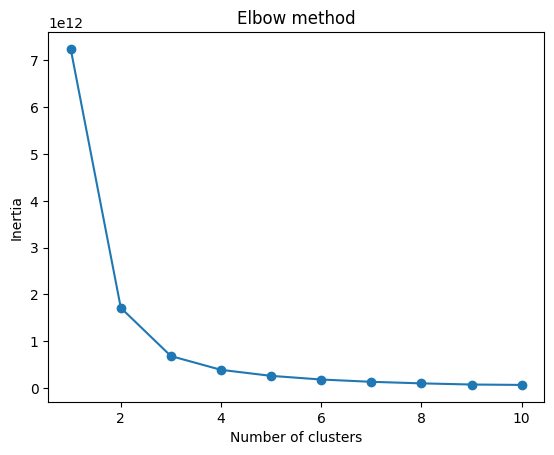

In [14]:
#plotting
plt.plot(range(1,11),inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow method")

# Testing the Model with a New Customer

In [15]:
#Creating a new customer
new_customer=pd.DataFrame([
    {
        "Age":42,
        "AnnualIncome":32000,
        "SpendingScore":45
    }
])

In [16]:
#predicting the new cusomter cluster group using our trained model
cluster=pipeline.predict(new_customer)
print("This new cusomter belongs to",cluster, "group")

This new cusomter belongs to [0] group


In [17]:
#creating a function to map the clusters to 
def get_customer_type(cluster):
    mapping={
        0:"Budget Shopper",
        1:"Regular Shopper",
        2:'Premimum Shopper'
    }
    return mapping.get(cluster, "Unknown")


In [18]:
#Creating 2nd new customer
new_customer_two=pd.DataFrame([
    {
        "Age":28,
        "AnnualIncome":70000,
        "SpendingScore":70
    }
])

cluster=pipeline.predict(new_customer_two)[0]
get_customer_type(cluster)

'Budget Shopper'

#### *One of the use cases: You can use your advertising budget effectively by showing high-value items to premium customers and lower-priced or discounted items to budget shoppers.*